In [2]:
from astropy.io import fits

In [ ]:
def open_file(file, header):
    hdul = fits.open(file, memmap=True)  

    if (header == "info"):
        hdul.info()
        return None

    if (header == "primary"):
        return hdul[0].header

    if (header == "data"):
        return hdul[1].header, hdul[1].data

MUSE = "../data/ADP.2019-03-04T22_21_26.534.fits"
ALMA = "../data/hh30-12co-minusdisk_9dot6kms.fits"
MIRI = "../data/jw01282-c1024_t029_miri_ch1-long_s3d.fits"
NIRSpec = "..data/jw01621-o001_t001_nirspec_g140h-f100lp_s3d.fits"

open_file(MUSE, "info")

Filename: ADP.2019-03-04T22_21_26.534.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1760   ()      
  1  DATA          1 ImageHDU        43   (319, 325, 3721)   float32   
  2  STAT          1 ImageHDU        43   (319, 325, 3721)   float32   


In [19]:
def metadata(file):
    hdul = fits.open(file, memmap=True)
    
    dims = {}
    for i, hdu in enumerate(hdul):
        if hdu.data is not None:
            shape = hdu.data.shape
            if len(shape) >= 2:
                x, y = shape[-2], shape[-1] 
                dims[i] = {
                    "name": hdu.name,
                    "shape": shape,
                    "x": x,
                    "y": y,
                    "pixels": x*y
                }
    hdul.close()
    return dims

metadata(MUSE)

{1: {'name': 'DATA',
  'shape': (3721, 325, 319),
  'x': 325,
  'y': 319,
  'pixels': 103675},
 2: {'name': 'STAT',
  'shape': (3721, 325, 319),
  'x': 325,
  'y': 319,
  'pixels': 103675}}

In [4]:
header, cube = open_file(MUSE, "data")

crval3 = header["CRVAL3"]   # starting wavelength
crpix3 = header["CRPIX3"]   # reference pixel
cd33 = header["CD3_3"]   # step per slice

def wavelength_for_slice(k):
    return crval3 + (k + 1 - crpix3) * cd33

print(crpix3)

# wavelength at slice 0
print(wavelength_for_slice(0))

# wavelength at slice 1000
print(wavelength_for_slice(1000))

import numpy as np

n_slices = header["NAXIS3"]
wavelengths = crval3 + (np.arange(1, n_slices+1) - crpix3) * cd33

print(wavelengths)
print(wavelengths.size)

1.0
4699.56005859375
5949.56005859375
[4699.56005859 4700.81005859 4702.06005859 ... 9347.06005859 9348.31005859
 9349.56005859]
3721


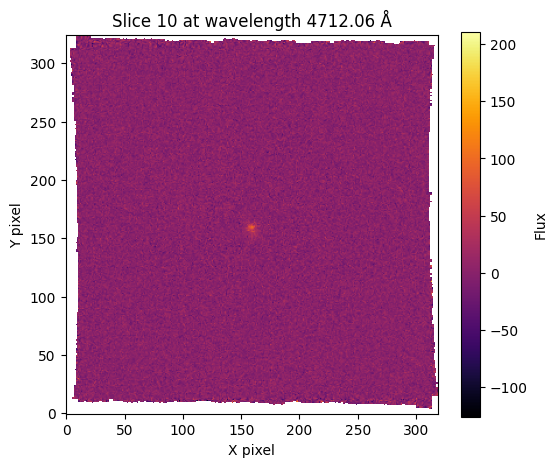

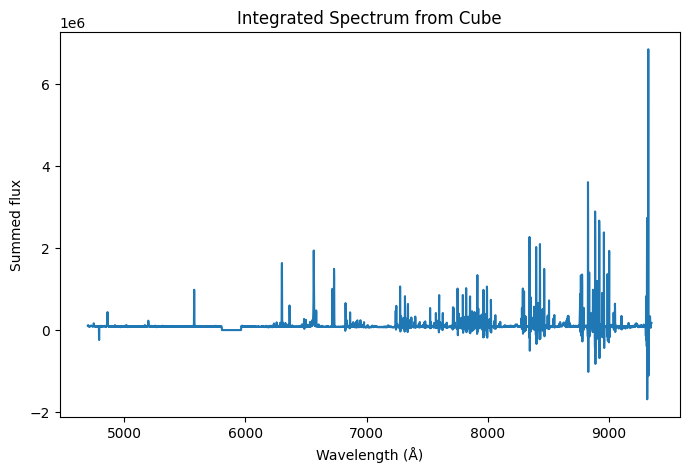

In [5]:
import matplotlib.pyplot as plt

slice_idx = 10  # slice
header, cube = open_file(MUSE, "data")
image = cube[slice_idx, :, :]

plt.figure(figsize=(6,5))
plt.imshow(image, origin='lower', cmap='inferno')
plt.colorbar(label='Flux')
plt.title(f"Slice {slice_idx} at wavelength {wavelengths[slice_idx]:.2f} Å")
plt.xlabel("X pixel")
plt.ylabel("Y pixel")
plt.show()

Nz, Ny, Nx = cube.shape

# sum over all pixels for each slice
spectrum = np.array([np.nansum(cube[k, :, :]) for k in range(Nz)])

# plot flux vs wavelength
plt.figure(figsize=(8,5))
plt.plot(wavelengths, spectrum)
plt.xlabel("Wavelength (Å)")
plt.ylabel("Summed flux")
plt.title("Integrated Spectrum from Cube")
plt.show()

In [6]:
open_file(MUSE, "info")

Filename: ADP.2019-03-04T22_21_26.534.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1760   ()      
  1  DATA          1 ImageHDU        43   (319, 325, 3721)   float32   
  2  STAT          1 ImageHDU        43   (319, 325, 3721)   float32   


In [4]:
open_file(MUSE, "primary")

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                    8 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
DATASUM = '         0'         / data unit checksum updated 2019-03-04T22:13:49 
COMMENT FITS (Flexible Image Transport System) format is defined in 'Astronomy  
COMMENT and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H   
DATE    = '2019-03-04T22:13:05' / file creation date (YYYY-MM-DDThh:mm:ss UT)   
ORIGIN  = 'ESO-PARANAL'        / European Southern Observatory                  
TELESCOP= 'ESO-VLT-U4'         / ESO <TEL>                                      
INSTRUME= 'MUSE    '           / Instrument used.                               
RA      =     67.9066768172694 / [deg] Image center (J2000)                     
DEC     =     18.20732908249

In [9]:
open_file(MUSE, "data")

(XTENSION= 'IMAGE   '           / IMAGE extension                                
 BITPIX  =                  -32 / number of bits per data pixel                  
 NAXIS   =                    3 / number of data axes                            
 NAXIS1  =                  319 / length of data axis 1                          
 NAXIS2  =                  325 / length of data axis 2                          
 NAXIS3  =                 3721 / length of data axis 3                          
 PCOUNT  =                    0 / required keyword; must = 0                     
 GCOUNT  =                    1 / required keyword; must = 1                     
 EXTNAME = 'DATA    '           / This extension contains data values            
 DATASUM = '1498238873'         / data unit checksum updated 2019-03-04T22:13:49 
 HDUCLASS= 'ESO     '           / class name (ESO format)                        
 HDUDOC  = 'DICD    '           / document with class description                
 HDUVERS = 'DICD

In [10]:
open_file(ALMA, "info")

Filename: hh30-12co-minusdisk_9dot6kms.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      46   (401, 401, 110, 1)   float32   


In [11]:
open_file(ALMA, "primary")

SIMPLE  =                    T         /                                        
BITPIX  =                  -32         /                                        
NAXIS   =                    4         /                                        
NAXIS1  =                  401         /                                        
NAXIS2  =                  401         /                                        
NAXIS3  =                  110         /                                        
NAXIS4  =                    1         /                                        
DATAMIN = -0.2063281647861E-01         /                                        
DATAMAX =  0.6078519672155E-01         /                                        
BUNIT   = 'Jy/beam     '               /                                        
CTYPE1  = 'RA---ARC    '               /                                        
CRVAL1  =  0.6790620583333E+02         /                                        
CDELT1  = -0.1388888974389E-

In [12]:
open_file(MIRI, "info")

Filename: jw01282-c1024_t029_miri_ch1-long_s3d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     379   ()      
  1  SCI           1 ImageHDU        89   (39, 33, 1400)   float32   
  2  ERR           1 ImageHDU        12   (39, 33, 1400)   float32   
  3  DQ            1 ImageHDU        12   (39, 33, 1400)   int32 (rescales to uint32)   
  4  WMAP          1 ImageHDU        10   (39, 33, 1400)   float32   
  5  HDRTAB        1 BinTableHDU    500   4R x 245C   [23A, 5A, 3A, 46A, 7A, 13A, 3A, 5A, 6A, 7A, 13A, 4A, L, D, D, 32A, 50A, 46A, 18A, 3A, 28A, 10A, 12A, 23A, 23A, 26A, 11A, 5A, 3A, 3A, 2A, 1A, 2A, 1A, L, 35A, 8A, 2A, 26A, 20A, 27A, 10A, K, L, L, L, L, 11A, 4A, 5A, D, D, D, D, D, D, 27A, D, D, 8A, 4A, 11A, 2A, 4A, 4A, 3A, 4A, K, 5A, 7A, D, D, D, D, D, D, D, D, D, 6A, K, K, K, K, K, K, K, K, K, D, D, D, D, D, D, D, D, D, K, K, L, L, K, K, D, 4A, K, K, K, K, K, K, 7A, K, K, D, D, 7A, 10A, D, D, D, D, D, D, D, D, D, D, D, D, D, 16A,

In [5]:
open_file(MIRI, "primary")

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
DATE    = '2025-09-11T18:42:39.699' / UTC date file created                     
ORIGIN  = 'STSCI   '           / Organization responsible for creating file     
TIMESYS = 'UTC     '           / principal time system for time-related keywords
TIMEUNIT= 's       '           / Default unit applicable to all time values     
FILENAME= 'jw01282-c1024_t029_miri_ch1-long_s3d.fits' / Name of the file        
SDP_VER = '2025_3a '           / Data Processing (DP) Software Version          
PRD_VER = 'PRDOPSSOC-071'      / S&OC Project Reference Database (PRD) Version  
OSS_VER = '8.5     '           / Observatory Scheduling Software (OSS) Version  
GSC_VER = 'GSC31   '        

In [15]:
open_file(MIRI, "data")

(XTENSION= 'IMAGE   '           / Image extension                                
 BITPIX  =                  -32 / array data type                                
 NAXIS   =                    3 / number of array dimensions                     
 NAXIS1  =                   39                                                  
 NAXIS2  =                   33                                                  
 NAXIS3  =                 1400                                                  
 PCOUNT  =                    0 / number of parameters                           
 GCOUNT  =                    1 / number of groups                               
 EXTNAME = 'SCI     '           / extension name                                 
 SRCTYPE = 'EXTENDED'           / Source type used for calibration               
 MJD-BEG =   59995.371884849534 / [d] exposure start time in MJD                 
 MJD-AVG =    59995.38058112268 / [d] exposure mid-point in MJD                  
 MJD-END =    59

In [16]:
open_file(NIRSpec, "info")

Filename: jw01621-o001_t001_nirspec_g140h-f100lp_s3d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     372   ()      
  1  SCI           1 ImageHDU        92   (53, 55, 3915)   float32   
  2  ERR           1 ImageHDU        12   (53, 55, 3915)   float32   
  3  DQ            1 ImageHDU        12   (53, 55, 3915)   int32 (rescales to uint32)   
  4  WMAP          1 ImageHDU        10   (53, 55, 3915)   float32   
  5  HDRTAB        1 BinTableHDU    512   8R x 251C   [23A, 5A, 3A, 39A, 7A, 13A, 6A, 5A, 6A, 7A, 13A, 4A, L, D, D, 32A, 49A, 83A, 16A, 2A, 33A, 10A, 12A, 23A, 23A, 26A, 11A, 5A, 3A, 3A, 2A, 1A, 2A, 1A, L, 24A, 4A, 2A, 26A, 20A, 27A, 10A, K, L, L, L, L, 4A, 12A, 5A, D, D, D, D, D, D, 27A, D, D, 8A, 7A, 4A, 6A, 5A, K, 4A, 3A, D, D, D, D, D, D, D, K, 5A, 7A, D, D, D, D, D, D, D, D, D, 12A, K, K, K, K, K, K, K, K, K, D, D, D, D, D, D, D, D, D, K, K, L, L, K, K, K, K, D, D, L, 4A, K, K, K, K, K, K, 14A, K, K, D, D, 7A, 10A, D, D

In [6]:
open_file(NIRSpec, "primary")

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
DATE    = '2025-09-20T16:32:57.877' / UTC date file created                     
ORIGIN  = 'STSCI   '           / Organization responsible for creating file     
TIMESYS = 'UTC     '           / principal time system for time-related keywords
TIMEUNIT= 's       '           / Default unit applicable to all time values     
FILENAME= 'jw01621-o001_t001_nirspec_g140h-f100lp_s3d.fits' / Name of the file  
SDP_VER = '2025_3a '           / Data Processing (DP) Software Version          
PRD_VER = 'PRDOPSSOC-071'      / S&OC Project Reference Database (PRD) Version  
OSS_VER = '8.4.14  '           / Observatory Scheduling Software (OSS) Version  
GSC_VER = 'GSC31   '        

In [17]:
open_file(NIRSpec, "data")

(XTENSION= 'IMAGE   '           / Image extension                                
 BITPIX  =                  -32 / array data type                                
 NAXIS   =                    3 / number of array dimensions                     
 NAXIS1  =                   53                                                  
 NAXIS2  =                   55                                                  
 NAXIS3  =                 3915                                                  
 PCOUNT  =                    0 / number of parameters                           
 GCOUNT  =                    1 / number of groups                               
 EXTNAME = 'SCI     '           / extension name                                 
 SRCTYPE = 'EXTENDED'           / Source type used for calibration               
 MJD-BEG =    59848.47674673611 / [d] exposure start time in MJD                 
 MJD-AVG =    59848.48887969184 / [d] exposure mid-point in MJD                  
 MJD-END =   598